In [1]:
# %pip install -q transformers datasets lm-eval accelerate tabulate matplotlib

In [2]:
import os
os.environ["HF_HOME"] = "/root/.cache/huggingface"
os.environ["HF_DATASETS_CACHE"] = "/root/.cache/huggingface/datasets"

In [3]:
from datasets import load_dataset
import datasets
from transformers import AutoTokenizer, PreTrainedTokenizerFast, AutoModelForCausalLM
from tokenizers import Tokenizer

In [4]:
import json, shutil, copy, pickle
#from tqdm import tqdm
from tqdm.notebook import tqdm
import math, torch
import importlib.metadata as md
import unicodedata
from tabulate import tabulate
import matplotlib.pyplot as plt

In [5]:
model_dir = "/Users/nirajh/Code/Language_adaptation/olmo2-7b-stage1"

#### Loading tokenizer and modifying its regex pattern

In [6]:
# Loading the tokenizer
tok = AutoTokenizer.from_pretrained(model_dir)

In [7]:
## Changing the regex pattern in the pre tokenizer, so that kannada words are split correctly
tj = json.loads(tok.backend_tokenizer.to_str())        # Getting the tokenizer's vocab, merges, special tokens, and pre-processing configs
split = tj["pre_tokenizer"]["pretokenizers"][0]        # Fetches the first pre-tokenizer (they are usually chained together under a Sequence)
old = split["pattern"]["Regex"]
new = old.replace(r"[^\r\n\p{L}\p{N}]?\p{L}+", r"[^\r\n\p{L}\p{N}]?[\p{L}\p{M}]+")
assert new != old, "pattern not found; print(old) and adjust"
split["pattern"]["Regex"] = new

In [8]:
# Checking its output
kn_tok = Tokenizer.from_str(json.dumps(tj))
text = "ನಮಸ್ಕಾರ ಕನ್ನಡ ಭಾಷೆಯಲ್ಲಿ"
print([text[s:e] for _, (s, e) in kn_tok.pre_tokenizer.pre_tokenize_str(text)])

['ನಮಸ್ಕಾರ', ' ಕನ್ನಡ', ' ಭಾಷೆಯಲ್ಲಿ']


In [9]:
base_tj = json.loads(kn_tok.to_str())          # regex-modified, no new merges yet
base_tj["normalizer"] = {"type": "NFC"}        # same normalization the merges were learned on

In [10]:
"asd_sdf".split('_')[-1]

'sdf'

In [11]:
# Initializing function to build a tokenizer with the new list of merges (path to merges list to be given)
def build_tokenizer(n, out_dir, new_merges, model_path):
    
    tkj = copy.deepcopy(base_tj)
    vocab = tkj["model"]["vocab"]
    merge_list = tkj["model"]["merges"]
    as_str = isinstance(merge_list[0], str)     # "a b" or ["a", "b"], depending on version
    next_id = max(max(vocab.values()), max(t["id"] for t in tkj["added_tokens"])) + 1

    for (a, b), _ in new_merges[:n]:
        if a + b not in vocab:                 # reuse the ID if the token already exists
            vocab[a + b] = next_id
            next_id += 1
        merge_list.append(f"{a} {b}" if as_str else [a, b])

    os.makedirs(out_dir, exist_ok=True)
    
    # return AutoTokenizer.from_pretrained(out_dir)
    # The issue with the above line: It doesn't just read tokenizer.json. It also reads tokenizer_config.json.
    # In recent transformers versions, model-specific tokenizer classes can rebuild parts of the pipeline, such as the pre-tokenizer and normalizer, from their own built-in defaults instead of using what’s in tokenizer.json
    # This means the tokenizer is not using the new regex pattern. It is using the pre-built one and fragmenting kannada words.

    hf_tok = PreTrainedTokenizerFast(
        tokenizer_object=Tokenizer.from_str(json.dumps(tkj)),
        eos_token="<|endoftext|>",
        pad_token="<|pad|>",
    )
    hf_tok.save_pretrained(out_dir)     # writes tokenizer.json + a config naming PreTrainedTokenizerFast

    # fail loudly if the pipeline didn't survive the save/load round trip
    reloaded = AutoTokenizer.from_pretrained(out_dir)
    test = "ನಮಸ್ಕಾರ ಕನ್ನಡ ಭಾಷೆಯಲ್ಲಿ"
    pieces = [test[s:e] for _, (s, e) in reloaded.backend_tokenizer.pre_tokenizer.pre_tokenize_str(test)]
    assert pieces == ["ನಮಸ್ಕಾರ", " ಕನ್ನಡ", " ಭಾಷೆಯಲ್ಲಿ"], pieces
    assert reloaded.backend_tokenizer.normalizer is not None, "NFC normalizer was dropped"
    return reloaded



#### Loading the new merges list

In [12]:
# Loading the new merges list
final_path = "/Users/nirajh/Code/Language_adaptation/merges_files/new_merges_excl.pkl"

with open(final_path, "rb") as f:
    merges_ = pickle.load(f)

#### Loading the evaluation set

In [13]:
# # Disable caching as it leads to permission errors on /workspace directories
# datasets.disable_caching()

In [14]:
kn_texts = []

with open("/Users/nirajh/Code/Language_adaptation/eval/kn_eval_texts.jsonl", "r", encoding="utf-8") as f:
    for line in f:
        data = json.loads(line)
        kn_texts.append(data["text"])

print(f"Successfully read {len(kn_texts)} lines.")   # Should be 1997


en_texts = []

with open("/Users/nirajh/Code/Language_adaptation/eval/en_eval_texts.jsonl", "r", encoding="utf-8") as f:
    for line in f:
        data = json.loads(line)
        en_texts.append(data["text"])

print(f"Successfully read {len(en_texts)} lines.")   # Should be 2000 lines

Successfully read 1997 lines.
Successfully read 2000 lines.


#### Function to calculate tokenizer stats

In [15]:
def tokenizer_stats(tok, texts, lang):
    n_tok = n_words = n_chars = n_frag = 0
    for t in tqdm(texts, leave=False, desc=f"Calculating tokenizer stats on {lang} eval set"):
        ids = tok(t, add_special_tokens=False)["input_ids"]
        n_tok += len(ids)
        n_words += len(t.split())
        n_chars += len(t)
        n_frag += sum("\ufffd" in tok.decode([i]) for i in ids)
    return {
        "fertility (tokens/word)": n_tok / n_words,
        "chars/token": n_chars / n_tok,
        "fragment rate": n_frag / n_tok,
    }

In [18]:
data = []

# for n in tqdm([0, 2000, 4000, 6000, 8000, 10000, 12000, 14000, 16000]):
for n in tqdm([0, "excl_3998"]):
    n_merges = int(n.split("_")[-1]) if isinstance(n, str) else n
    variant = n.rsplit("_", 1)[0] if isinstance(n, str) else "none"
    
    t = build_tokenizer(n_merges, f"/Users/nirajh/Code/Language_adaptation/tokenizers/kn_{n}", merges_, model_dir)
    assert all(t.decode(t.encode(x, add_special_tokens=False)) == unicodedata.normalize("NFC", x)
               for x in kn_texts + en_texts)                     # exact round-trip
    
    kn_stats = tokenizer_stats(t, kn_texts, "Kannada")
    en_stats = tokenizer_stats(t, en_texts, "English")
    
    data.append([n_merges, len(t), "Kannada", *kn_stats.values(), variant])
    data.append([n_merges, len(t), "English", *en_stats.values(), variant])

headers = ["Num of new merges", "Vocab size", "Test set language", *kn_stats.keys(), "Variant"]
print(tabulate(data, headers=headers, tablefmt="grid"))


  0%|          | 0/2 [00:00<?, ?it/s]

Calculating tokenizer stats on Kannada eval set:   0%|          | 0/1997 [00:00<?, ?it/s]

Calculating tokenizer stats on English eval set:   0%|          | 0/2000 [00:00<?, ?it/s]

Calculating tokenizer stats on Kannada eval set:   0%|          | 0/1997 [00:00<?, ?it/s]

Calculating tokenizer stats on English eval set:   0%|          | 0/2000 [00:00<?, ?it/s]

+---------------------+--------------+---------------------+---------------------------+---------------+-----------------+-----------+
|   Num of new merges |   Vocab size | Test set language   |   fertility (tokens/word) |   chars/token |   fragment rate | Variant   |
+=====================+==============+=====================+===========================+===============+=================+===========+
|                   0 |       100278 | Kannada             |                  13.5697  |      0.595751 |      0.977612   | none      |
+---------------------+--------------+---------------------+---------------------------+---------------+-----------------+-----------+
|                   0 |       100278 | English             |                   1.28049 |      4.79857  |      0.00136234 | none      |
+---------------------+--------------+---------------------+---------------------------+---------------+-----------------+-----------+
|                3998 |       104276 | Kannada         

Ensuring that the modified regex pattern was used to calculate the above metrices (word boundaries should be correct)

In [19]:
t = AutoTokenizer.from_pretrained("/Users/nirajh/Code/Language_adaptation/tokenizers/kn_excl_3998")
text = "ನಮಸ್ಕಾರ ಕನ್ನಡ ಭಾಷೆಯಲ್ಲಿ"
print([text[s:e] for _, (s, e) in t.backend_tokenizer.pre_tokenizer.pre_tokenize_str(text)])

['ನಮಸ್ಕಾರ', ' ಕನ್ನಡ', ' ಭಾಷೆಯಲ್ಲಿ']


In [20]:
print(json.load(open(f"{model_dir}/tokenizer_config.json")).get("tokenizer_class"), md.version("transformers"))
print(t.backend_tokenizer.normalizer, t.backend_tokenizer.pre_tokenizer)

GPT2Tokenizer 5.18.0
NFC() Sequence(pretokenizers=[Split(pattern=Regex("(?i:'s|'t|'re|'ve|'m|'ll|'d)|[^\r\n\p{L}\p{N}]?[\p{L}\p{M}]+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]+[\r\n]*|\s..."), behavior=Removed, invert=True), ByteLevel(add_prefix_space=False, trim_offsets=True, use_regex=False)])


In [21]:
# data rows: [n, vocab_size, language, fertility, chars/token, fragment rate]
def series(lang, col):
    rows = sorted((r for r in data if r[2] == lang), key=lambda r: r[0])
    return [r[0] for r in rows], [r[col] for r in rows]

In [22]:
metrics = [(3, "Fertility (tokens/word)", "fertility"),
           (4, "Chars/token", "chars_per_token"),
           (5, "Fragment rate", "fragment_rate")]

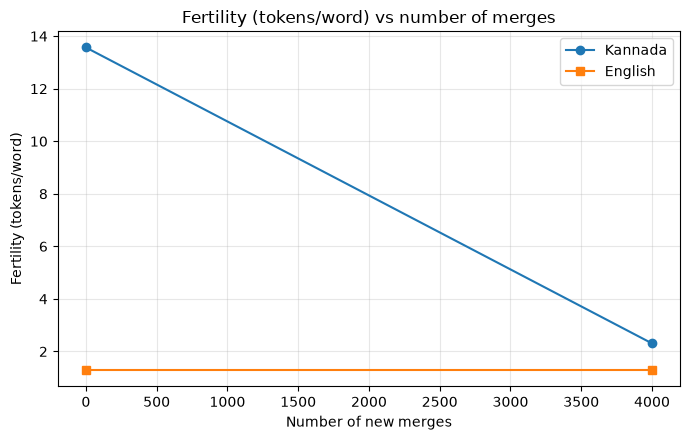

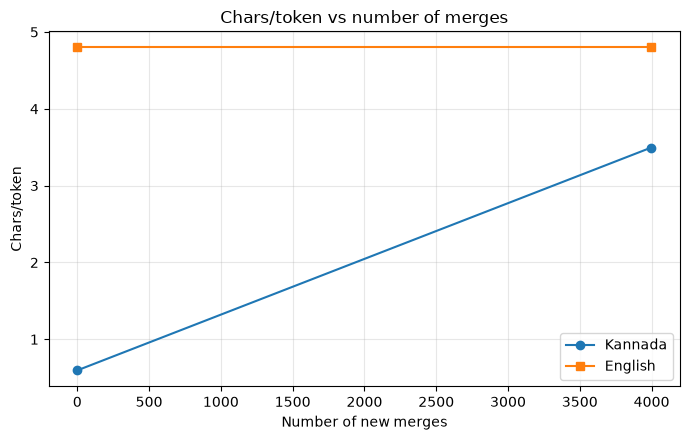

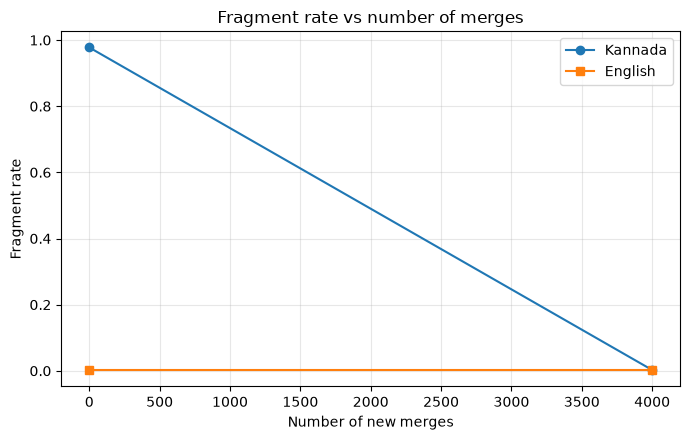

In [23]:
# Graphs 1-3: one metric each, Kannada vs English
for col, label, fname in metrics:
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for lang, marker in [("Kannada", "o"), ("English", "s")]:
        x, y = series(lang, col)
        ax.plot(x, y, marker=marker, label=lang)
    ax.set_xlabel("Number of new merges")
    ax.set_ylabel(label)
    ax.set_title(f"{label} vs number of merges")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    #fig.savefig(f"{out_dir}/{fname}.png", dpi=150)
    plt.show()

### Calculating Bits Per Byte (BPB)

In [ ]:
# Loading the model from disk
model = AutoModelForCausalLM.from_pretrained(model_dir, dtype="bfloat16", device_map="cuda")

Loading weights:   0%|          | 0/355 [00:00<?, ?it/s]

In [ ]:
@torch.no_grad()
def bits_per_byte(model, tok, texts, max_len=4096, slice_len=1024):
    
    total_nll, total_bytes = 0.0, 0
    
    for t in tqdm(texts, leave=False):
        ids = tok(t, return_tensors="pt", add_special_tokens=False)["input_ids"][0]
        
        for s in range(0, len(ids) - 1, max_len):
            chunk = ids[s : s + max_len + 1].unsqueeze(0).to(model.device)
            if chunk.shape[1] < 2:
                continue
            inp, tgt = chunk[:, :-1], chunk[:, 1:]
            hidden = model.model(inp).last_hidden_state          # (1, L, d)
            
            for j in range(0, inp.shape[1], slice_len):
                logits = model.lm_head(hidden[:, j : j + slice_len]).float()
                total_nll += torch.nn.functional.cross_entropy(
                    logits[0], tgt[0, j : j + slice_len], reduction="sum"
                ).item()
                
        total_bytes += len(t.encode("utf-8"))
        
    return total_nll / (math.log(2) * total_bytes)

In [ ]:
bpb_data = []

for n in tqdm([0, 2000, 6000, 10000, 16000]):

    t = build_tokenizer(n, f"/workspace/language_adaptation/tokenizers/kn_{n}", merges_, model_dir)
    model.resize_token_embeddings(len(t), pad_to_multiple_of=128)

    bpb = bits_per_byte(model, t, kn_texts)

    bpb_data.append([n, bpb])

    print(f"BPB with {n} merges is {bpb}")


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/1997 [00:00<?, ?it/s]

BPB with 0 merges is 0.8476992618287529


[transformers] The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
[transformers] The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`


  0%|          | 0/1997 [00:00<?, ?it/s]

BPB with 2000 merges is 2.8918664063783064


... (2 outputs left out)

  0%|          | 0/1997 [00:00<?, ?it/s]

BPB with 10000 merges is 1.938358201399477


  0%|          | 0/1997 [00:00<?, ?it/s]

BPB with 16000 merges is 1.770536406691582


In [ ]:
print(*bpb_data)

[0, 0.8476992618287529] [2000, 2.8918664063783064] [6000, 2.1668443254324377] [10000, 1.938358201399477] [16000, 1.770536406691582]


In [ ]:
bpb_headers = ["Num_merges", "BPB"]
print(tabulate(bpb_data, headers=bpb_headers, tablefmt="grid"))

+--------------+----------+
|   Num_merges |      BPB |
+==============+==========+
|            0 | 0.847699 |
+--------------+----------+
|         2000 | 2.89187  |
+--------------+----------+
|         6000 | 2.16684  |
+--------------+----------+
|        10000 | 1.93836  |
+--------------+----------+
|        16000 | 1.77054  |
+--------------+----------+


In [ ]:
# Graph: Kannada fertility and BPB on twin y-axes
x_f, y_f = series("Kannada", 3)
bpb_rows = sorted(bpb_data, key=lambda r: r[0])
x_b, y_b = [r[0] for r in bpb_rows], [r[1] for r in bpb_rows]

fig, ax1 = plt.subplots(figsize=(7, 4.5))
l1 = ax1.plot(x_f, y_f, marker="o", color="tab:blue", label="Kannada fertility")
ax1.set_xlabel("Number of new merges")
ax1.set_ylabel("Fertility (tokens/word)", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
l2 = ax2.plot(x_b, y_b, marker="s", color="tab:red", label="Kannada BPB (before continued pretraining)")
ax2.set_ylabel("Bits per byte", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

ax1.legend(l1 + l2, [l.get_label() for l in l1 + l2], loc="upper right")
ax1.set_title("Kannada fertility and BPB vs number of merges")
ax1.grid(alpha=0.3)
fig.tight_layout()
# fig.savefig(f"{out_dir}/fertility_and_bpb.png", dpi=150)
plt.show()

TypeError: '<' not supported between instances of 'str' and 'int'